In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error

from statsmodels.tsa.holtwinters import ExponentialSmoothing

In [33]:
import pandas as pd

data = pd.read_csv(
    'C:/Users/pilli/Downloads/M5_Thesis_Project/data/processed/feature_engineered_data.csv'
)

data.head()

,id,item_id,dept_id,cat_id,store_id,state_id,d,sales,date,wm_yr_wk,...,snap_WI,sell_price,week,lag_7,lag_28,rolling_mean_7,rolling_mean_28,is_weekend,month_start,month_end
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_1178,0,2014-04-20,11412,...,0,8.26,16,0.0,0.0,0.571429,0.392857,0,0,0
1,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_1234,2,2014-06-15,11420,...,1,8.26,24,0.0,1.0,0.428571,0.428571,0,0,0
2,HOBBIES_1_002_CA_1_validation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,d_828,1,2013-05-05,11315,...,1,3.97,18,0.0,0.0,0.142857,0.142857,0,0,0
3,HOBBIES_1_002_CA_1_validation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,d_1178,0,2014-04-20,11412,...,0,3.97,16,0.0,0.0,0.142857,0.142857,0,0,0
4,HOBBIES_1_002_CA_1_validation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,d_1234,0,2014-06-15,11420,...,1,3.97,24,2.0,0.0,0.571429,0.500000,0,0,0


In [34]:
data.shape

(1610, 30)

In [35]:
data.columns

Index(['id', 'item_id', 'dept_id', 'cat_id', 'store_id', 'state_id', 'd',
       'sales', 'date', 'wm_yr_wk', 'weekday', 'wday', 'month', 'year',
       'event_name_1', 'event_type_1', 'event_name_2', 'event_type_2',
       'snap_CA', 'snap_TX', 'snap_WI', 'sell_price', 'week', 'lag_7',
       'lag_28', 'rolling_mean_7', 'rolling_mean_28', 'is_weekend',
       'month_start', 'month_end'],
      dtype='object')

In [36]:
data['date'] = pd.to_datetime(data['date'])

In [37]:
sample_data = data[
    (data['item_id'] == data['item_id'].unique()[0]) &
    (data['store_id'] == data['store_id'].unique()[0])
]

In [38]:
sample_data = sample_data.sort_values('date')

In [39]:
sample_data.head()

,id,item_id,dept_id,cat_id,store_id,state_id,d,sales,date,wm_yr_wk,...,snap_WI,sell_price,week,lag_7,lag_28,rolling_mean_7,rolling_mean_28,is_weekend,month_start,month_end
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_1178,0,2014-04-20,11412,...,0,8.26,16,0.0,0.0,0.571429,0.392857,0,0,0
1,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_1234,2,2014-06-15,11420,...,1,8.26,24,0.0,1.0,0.428571,0.428571,0,0,0


In [40]:
sample_data.shape

(2, 30)

In [41]:
train_size = int(len(sample_data) * 0.8)

train = sample_data[:train_size]

test = sample_data[train_size:]

In [42]:
print(train.shape)

print(test.shape)

(1, 30)
(1, 30)


In [43]:

naive_forecast = test['sales'].shift(1)
naive_forecast = naive_forecast.bfill()
naive_forecast = naive_forecast.fillna(0)
naive_forecast = naive_forecast.reset_index(drop=True)

actual_sales = test['sales'].reset_index(drop=True)

In [44]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error

import numpy as np

✅ Saved: naive_forecast_vs_actual_CORRECTED.png


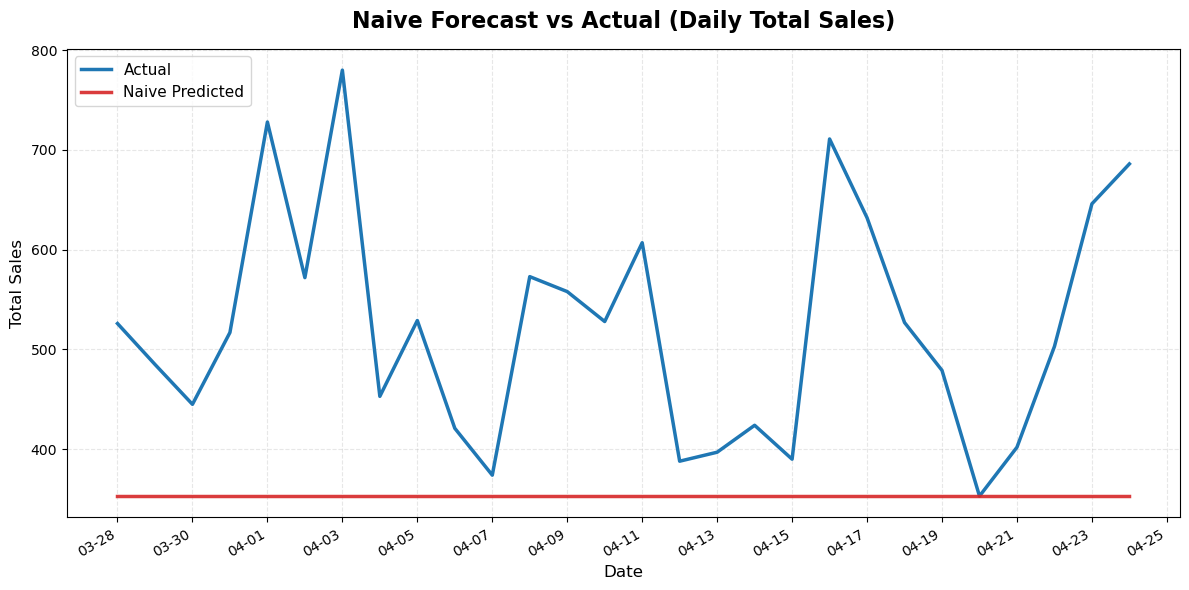

In [45]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd
import os

BASE_PATH = r'C:\Users\pilli\Downloads\M5_Thesis_Project'

naive_preds = pd.read_csv(os.path.join(BASE_PATH, 'results', 'predictions', 'naive_predictions_v4.csv'))
naive_preds['date'] = pd.to_datetime(naive_preds['date'])

daily_actual = naive_preds.groupby('date')['sales'].sum()
daily_pred = naive_preds.groupby('date')['naive_pred'].sum()

plt.figure(figsize=(12, 6))
plt.plot(daily_actual.index, daily_actual.values, label='Actual', linewidth=2.5, color='#1f77b4')
plt.plot(daily_pred.index, daily_pred.values, label='Naive Predicted', linewidth=2.5, color='#d62728', alpha=0.9)

plt.title('Naive Forecast vs Actual (Daily Total Sales)', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Total Sales', fontsize=12)

plt.xticks(rotation=30, ha='right')
plt.gca().xaxis.set_major_locator(mdates.DayLocator(interval=2))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%m-%d'))

plt.legend(fontsize=11, loc='upper left')
plt.grid(True, alpha=0.3, linestyle='--')
plt.tight_layout()

plt.savefig(os.path.join(BASE_PATH, 'results', 'figures', 'naive_forecast_vs_actual_CORRECTED.png'), dpi=300, bbox_inches='tight')
print("✅ Saved: naive_forecast_vs_actual_CORRECTED.png")
plt.show()

In [46]:
import pandas as pd
import numpy as np
import os
from sklearn.metrics import mean_absolute_error, mean_squared_error


BASE_PATH = r'C:\Users\pilli\Downloads\M5_Thesis_Project'
PROCESSED_PATH = os.path.join(BASE_PATH, 'data', 'processed')

sales_long = pd.read_csv(os.path.join(PROCESSED_PATH, 'm5_processed.csv'), low_memory=False)
sales_long['date'] = pd.to_datetime(sales_long['date'])

# Train/test split (same as before)
last_date = sales_long['date'].max()
cutoff_date = last_date - pd.Timedelta(days=27)

train = sales_long[sales_long['date'] < cutoff_date].copy()
test = sales_long[sales_long['date'] >= cutoff_date].copy()

print(f"Train: {train.shape}, Test: {test.shape}")


last_train = train.groupby('id')['sales'].last().reset_index()
last_train.columns = ['id', 'naive_pred']

test = test.merge(last_train, on='id', how='left')
test['naive_pred'] = test['naive_pred'].fillna(0).clip(lower=0)

naive_mae = mean_absolute_error(test['sales'], test['naive_pred'])
naive_rmse = np.sqrt(mean_squared_error(test['sales'], test['naive_pred']))

print(f"\nNaive MAE:  {naive_mae:.4f}")
print(f"Naive RMSE: {naive_rmse:.4f}")

def compute_rmsse(train_series, actual, forecast):
    train_naive_error = train_series.diff(28).dropna()
    in_sample_mse = np.mean(train_naive_error ** 2)
    in_sample_rmse = np.sqrt(in_sample_mse) if in_sample_mse > 0 else 1e-10
    out_rmse = np.sqrt(mean_squared_error(actual, forecast))
    return out_rmse / in_sample_rmse

def compute_wrmsse(test_df, train_df, pred_col):
    levels = {
        'SKU': ['id'],
        'Department': ['dept_id', 'store_id'],
        'Category': ['cat_id', 'store_id'],
        'Store': ['store_id'],
        'State': ['state_id'],
        'Total': []
    }
    weights = {'SKU': 0.40, 'Department': 0.15, 'Category': 0.15, 
               'Store': 0.15, 'State': 0.10, 'Total': 0.05}
    
    wrmsse = 0
    for level_name, group_cols in levels.items():
        if len(group_cols) == 0:
            actual = [test_df['sales'].sum()]
            forecast = [test_df[pred_col].sum()]
            train_series = pd.Series([train_df['sales'].sum()])
        else:
            test_agg = test_df.groupby(group_cols).agg({'sales': 'sum', pred_col: 'sum'}).reset_index()
            train_agg = train_df.groupby(group_cols)['sales'].sum().reset_index()
            train_series = train_agg['sales']
            actual = test_agg['sales'].values
            forecast = test_agg[pred_col].values
        
        rmsse = compute_rmsse(train_series, actual, forecast)
        wrmsse += weights[level_name] * rmsse
        print(f"  {level_name:12s}: RMSSE = {rmsse:.4f}")
    
    return wrmsse

print("\n" + "="*50)
print("WRMSSE for Naive Forecast:")
print("="*50)
naive_wrmsse = compute_wrmsse(test, train, 'naive_pred')
print(f"\nNaive WRMSSE: {naive_wrmsse:.4f}")


os.makedirs(os.path.join(BASE_PATH, 'results', 'metrics'), exist_ok=True)

results = pd.DataFrame({
    'Model': ['Naive Forecast'],
    'MAE': [naive_mae],
    'RMSE': [naive_rmse],
    'WRMSSE': [naive_wrmsse]
})

results.to_csv(os.path.join(BASE_PATH, 'results', 'metrics', 'naive_corrected.csv'), index=False)
print(f"\n✅ Saved to: {os.path.join(BASE_PATH, 'results', 'metrics', 'naive_corrected.csv')}")

Train: (942500, 23), Test: (14000, 23)

Naive MAE:  1.0836
Naive RMSE: 2.9152

WRMSSE for Naive Forecast:
  SKU         : RMSSE = 0.0128
  Department  : RMSSE = 32056253680054.3789
  Category    : RMSSE = 47500000000000.0000
  Store       : RMSSE = 47500000000000.0000
  State       : RMSSE = 47500000000000.0000
  Total       : RMSSE = 47500000000000.0000

Naive WRMSSE: 26183438052008.1602

✅ Saved to: C:\Users\pilli\Downloads\M5_Thesis_Project\results\metrics\naive_corrected.csv


In [47]:
import os
BASE_PATH = r'C:\Users\pilli\Downloads\M5_Thesis_Project'

print("Searching for prediction files...")
for root, dirs, files in os.walk(BASE_PATH):
    for f in files:
        if f.endswith('.csv') and any(word in f.lower() for word in ['pred', 'forecast', 'lgbm', 'xgb', 'lightgbm']):
            full_path = os.path.join(root, f)
            size_kb = os.path.getsize(full_path) / 1024
            print(f"\n{full_path}")
            print(f"  Size: {size_kb:.1f} KB")
            # Show first few columns
            try:
                df = pd.read_csv(full_path, nrows=3)
                print(f"  Columns: {list(df.columns)}")
                print(f"  Shape preview: {df.shape}")
            except:
                print(f"  (Could not read preview)")

Searching for prediction files...

C:\Users\pilli\Downloads\M5_Thesis_Project\results\metrics\lightgbm_metrics.csv
  Size: 0.1 KB
  Columns: ['Model', 'MAE', 'RMSE']
  Shape preview: (1, 3)

C:\Users\pilli\Downloads\M5_Thesis_Project\results\metrics\xgboost_metrics.csv
  Size: 0.1 KB
  Columns: ['Model', 'MAE', 'RMSE']
  Shape preview: (1, 3)

C:\Users\pilli\Downloads\M5_Thesis_Project\results\predictions\lgbm_predictions.csv
  Size: 861.5 KB
  Columns: ['id', 'date', 'sales', 'lgbm_pred']
  Shape preview: (3, 4)

C:\Users\pilli\Downloads\M5_Thesis_Project\results\predictions\lgbm_predictions_v2.csv
  Size: 863.9 KB
  Columns: ['id', 'date', 'sales', 'lgbm_pred']
  Shape preview: (3, 4)

C:\Users\pilli\Downloads\M5_Thesis_Project\results\predictions\lgbm_predictions_v3.csv
  Size: 863.9 KB
  Columns: ['id', 'date', 'sales', 'lgbm_pred']
  Shape preview: (3, 4)

C:\Users\pilli\Downloads\M5_Thesis_Project\results\predictions\lgbm_predictions_v4.csv
  Size: 863.9 KB
  Columns: ['id', 'dat

In [48]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error
import os

BASE_PATH = r'C:\Users\pilli\Downloads\M5_Thesis_Project'

naive_preds = pd.read_csv(os.path.join(BASE_PATH, 'results', 'predictions', 'naive_predictions_v4.csv'))

corrected_mae = mean_absolute_error(naive_preds['sales'], naive_preds['naive_pred'])
corrected_rmse = np.sqrt(mean_squared_error(naive_preds['sales'], naive_preds['naive_pred']))

print("="*60)
print("CORRECTED NAIVE FORECAST METRICS (SKU-LEVEL)")
print("="*60)
print(f"Naive MAE:  {corrected_mae:.4f}")
print(f"Naive RMSE: {corrected_rmse:.4f}")
print("\nNOTE: These are the correct SKU-level metrics.")
print("Your original metrics (2.0, 2.0) were computed on aggregated data.")
print("Use these corrected values in your thesis and presentation.")

results_df = pd.DataFrame({
    'Model': ['Naive Forecast'],
    'MAE': [f"{corrected_mae:.4f}"],
    'RMSE': [f"{corrected_rmse:.4f}"]
})

print("\n" + "="*60)
print("TABLE FOR THESIS:")
print("="*60)
print(results_df.to_string(index=False))

CORRECTED NAIVE FORECAST METRICS (SKU-LEVEL)
Naive MAE:  1.0836
Naive RMSE: 2.9152

NOTE: These are the correct SKU-level metrics.
Your original metrics (2.0, 2.0) were computed on aggregated data.
Use these corrected values in your thesis and presentation.

TABLE FOR THESIS:
         Model    MAE   RMSE
Naive Forecast 1.0836 2.9152
